# Complexity-02c — La transition de phase sans mur : les systèmes linéaires aléatoires sur GF(2)

**Navigation** : [Index](README.md) | [02 — Vérifier ou trouver : P, NP](Complexity-02-P-NP-Reduction-CSharp.ipynb) | [03 — Plus de temps, plus de problèmes](Complexity-03-HierarchieTemporelle-Python.ipynb) | [jumeau Python](Complexity-02c-XOR-SAT-Phase-Transition-Python.ipynb)

**Niveau** : Recherche (approfondissement du palier 02)

**Hommage** : le seuil de satisfaisabilité des systèmes d'équations linéaires aléatoires sur $\mathrm{GF}(2)$ (Mézard, Ricci-Tersenghi & Zecchina, 2003)

## 0. Pourquoi ce notebook

Approfondissement du palier [02 — P, NP et la réduction](Complexity-02-P-NP-Reduction-CSharp.ipynb),
compagnon de l'accrétion **02b** (la transition de phase du **3-SAT** aléatoire contre la densité $m/n$).

L'accrétion 02b mesure un fait célèbre : le 3-SAT aléatoire a un **seuil de satisfaisabilité**
vers $m/n \approx 4{,}267$, et le coût du solveur (les nœuds DPLL) **pic au même endroit**.
Le 3-SAT est NP-complet : ce pic est la signature du **mur** exponentiel.

Cette accrétion pose la question que 02b laisse ouverte :

> Une transition de satisfaisabilité n'implique-t-elle **toujours** un mur de coût ?

La réponse est **non**, et elle se mesure sur les **systèmes d'équations linéaires aléatoires
sur $\mathrm{GF}(2)$** : $m$ équations linéaires à $n$ inconnues, coefficients et membres de
droite tirés au hasard. Ce système a un seuil de satisfaisabilité **net à $m/n = 1$** — un fait
d'algèbre linéaire (la matrice aléatoire devient de **rang plein** à $m = n$) — mais il est
**résolu en temps polynomial** par élimination de Gauss, **sans** que le coût décolle au seuil.
C'est le contre-exemple propre : **un seuil sans mur**. Le point est exactement la distinction
P/NP du palier 02 : le pic de coût du 3-SAT vient de la **NP-complétude**, pas du seuil.

> Le 2-XOR-SAT ($x_i \oplus x_j = c$, deux variables par équation) est un cas **sparse** de cette
> même famille : son seuil de satisfaisabilité est à $m/n = 1/2$, **deux fois plus bas** que celui
> du modèle dense — c'est le **3**-XOR-SAT, de seuil $m/n \approx 0{,}918$, qui en reste proche.
> Nous travaillons sur le modèle **dense** (chaque coefficient tiré indépendamment), dont le seuil
> est **rigoureusement** $m/n = 1$.

## 1. Le problème : un système d'équations linéaires aléatoire sur GF(2)

On tire au hasard une matrice $A$ de $m$ lignes et $n$ colonnes sur $\mathrm{GF}(2)$ (chaque
coefficient vaut $0$ ou $1$ avec probabilité $1/2$) et un membre de droite $b \in \mathrm{GF}(2)^m$.
L'instance est le système $A x = b$ ; il est **satisfaisable** s'il est compatible. L'addition
sur $\mathrm{GF}(2)$ est l'`XOR` : c'est pour ça qu'on parle de « systèmes XOR ».

L'élimination de Gauss y décide de la compatibilité en $O(n^3)$ et donne le **rang** $r$ :
s'il y a solution, il y en a exactement $2^{n-r}$ (les $n-r$ variables libres). Nous allons
tracer $P(\text{sat})$ et le rang contre la densité $m/n$.

In [1]:
using System;
using System.Collections.Generic;
using System.Globalization;
using System.Linq;
using System.Text;

CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;

// Les tirages C# utilisent System.Random, distinct du générateur NumPy.
// Chaque expérience repart de la graine 42, comme dans le protocole source.
(int[,] A, int[] b) gen_instance(int m, int n, Random rng)
{
    var A = new int[m, n];
    var b = new int[m];
    for (int i = 0; i < m; i++)
        for (int j = 0; j < n; j++)
            A[i, j] = rng.Next(2);
    for (int i = 0; i < m; i++)
        b[i] = rng.Next(2);
    return (A, b);
}

(bool sat, int rang, int libres) gauss_gf2(int[,] A, int[] b)
{
    int m = A.GetLength(0), n = A.GetLength(1);
    if (b.Length != m) throw new ArgumentException("Dimensions incompatibles");
    var M = new int[m, n + 1]; // m x (n+1)
    for (int i = 0; i < m; i++)
    {
        for (int j = 0; j < n; j++) M[i, j] = A[i, j];
        M[i, n] = b[i];
    }
    int rang = 0;
    for (int col = 0; col < n; col++)
    {
        int pivot = rang;
        while (pivot < m && M[pivot, col] == 0) pivot++;
        if (pivot == m) continue;
        for (int j = 0; j <= n; j++)
        {
            int tmp = M[rang, j];
            M[rang, j] = M[pivot, j];
            M[pivot, j] = tmp;
        }
        for (int row = 0; row < m; row++)
            if (row != rang && M[row, col] == 1)
                for (int j = 0; j <= n; j++) M[row, j] ^= M[rang, j];
        rang++;
    }
    // incohérent s'il existe une ligne [ 0 ... 0 | 1 ]
    for (int row = 0; row < m; row++)
    {
        bool zero = true;
        for (int col = 0; col < n; col++)
            if (M[row, col] != 0) { zero = false; break; }
        if (zero && M[row, n] == 1) return (false, rang, n - rang);
    }
    return (true, rang, n - rang);
}

void verifier(bool condition, string message)
{
    if (!condition) throw new InvalidOperationException(message);
}

// Les séries du graphique sont les valeurs affichées dans les tables.
string graphique_svg(double[] x, double[][] series, string[] couleurs, string titre, string axeX, string axeY, double ymin, double ymax, double[] reperes)
{
    if (x.Length < 2 || series.Length != couleurs.Length || series.Any(s => s.Length != x.Length) || ymax <= ymin)
        throw new ArgumentException("Données de graphique incompatibles");
    double xmin = x.Min(), xmax = x.Max();
    if (xmax <= xmin) throw new ArgumentException("Abscisses constantes");
    string f(double v) => v.ToString("0.##", CultureInfo.InvariantCulture);
    string ech(string s) => System.Security.SecurityElement.Escape(s) ?? "";
    double px(double v) => 70 + 600 * (v - xmin) / (xmax - xmin);
    double py(double v) => 330 - 270 * (v - ymin) / (ymax - ymin);
    var svg = new StringBuilder();
    svg.Append("<svg xmlns='http://www.w3.org/2000/svg' width='720' height='400' viewBox='0 0 720 400'>");
    svg.Append("<rect width='720' height='400' fill='white'/>");
    svg.Append("<text x='360' y='25' text-anchor='middle' font-size='15'>" + ech(titre) + "</text>");
    for (int i = 0; i <= 5; i++)
    {
        double xv = xmin + (xmax - xmin) * i / 5.0;
        double yv = ymin + (ymax - ymin) * i / 5.0;
        svg.Append("<line x1='70' y1='" + f(py(yv)) + "' x2='670' y2='" + f(py(yv)) + "' stroke='#ddd'/>");
        svg.Append("<text x='62' y='" + f(py(yv) + 4) + "' text-anchor='end' font-size='11'>" + f(yv) + "</text>");
        svg.Append("<text x='" + f(px(xv)) + "' y='348' text-anchor='middle' font-size='11'>" + f(xv) + "</text>");
    }
    foreach (double r in reperes)
        if (r >= xmin && r <= xmax)
            svg.Append("<line x1='" + f(px(r)) + "' y1='60' x2='" + f(px(r)) + "' y2='330' stroke='gray' stroke-dasharray='5,4'/>");
    svg.Append("<path d='M70 60 V330 H670' fill='none' stroke='black'/>");
    for (int k = 0; k < series.Length; k++)
    {
        var points = new List<string>();
        for (int i = 0; i < x.Length; i++) points.Add(f(px(x[i])) + "," + f(py(series[k][i])));
        svg.Append("<polyline fill='none' stroke='" + ech(couleurs[k]) + "' stroke-width='2' points='" + string.Join(" ", points) + "'/>");
    }
    svg.Append("<text x='370' y='380' text-anchor='middle' font-size='13'>" + ech(axeX) + "</text>");
    svg.Append("<text x='15' y='195' text-anchor='middle' transform='rotate(-90 15 195)' font-size='13'>" + ech(axeY) + "</text></svg>");
    return svg.ToString();
}

### Lecture — un système linéaire, un rang

Chaque équation est une ligne de $A$ ; l'instance est $Ax=b$ sur $\mathrm{GF}(2)$.
Le **rang** $r$ est l'objet à suivre : il croît avec le nombre d'équations $m$, puis
**sature à $n$**. Tant que $r < m$ il reste des équations redondantes ; le système est
compatible s'il n'y a pas de ligne contradictoire $0 = 1$ après élimination.

Pourquoi ce seul nombre gouverne toute la suite : les $r$ variables pivots déterminent une
solution, et chaque affectation des $n - r$ variables libres en donne une — un système
satisfaisable a donc exactement $2^{\,n-r}$ solutions. Chaque équation **indépendante** de
plus divise ce compte par 2 : avec $m = n + s$ équations, il ne reste que $2^{-s}$ chances
de compatibilité. Le seuil de la section 3, la forme du coût de la section 4 et l'affûtage
de la section 6 sont trois lectures de cette seule arithmétique.

## 2. L'oracle : Gauss confronté à l'énumération exhaustive

Avant de faire confiance aux courbes, on vérifie le solveur. Sur de petites instances
($n \le 10$), on énumère **toutes** les $2^n$ affectations : c'est un oracle indépendant,
brutal mais infaillible. Le compte de désaccords doit être **zéro**.

In [2]:
// Oracle indépendant : essayer chacune des affectations possibles.
bool exhaustive_sat(int[,] A, int[] b)
{
    int m = A.GetLength(0), n = A.GetLength(1);
    for (int x = 0; x < (1 << n); x++)
    {
        bool satisfait = true;
        for (int i = 0; i < m && satisfait; i++)
        {
            int somme = 0;
            for (int j = 0; j < n; j++) somme ^= A[i, j] & ((x >> j) & 1);
            if (somme != b[i]) satisfait = false;
        }
        if (satisfait) return true;
    }
    return false;
}

// Même protocole et même graine, avec un générateur distinct de NumPy.
var rngOracle = new Random(42);
int disagreements = 0, tried = 0;
for (int nOracle = 6; nOracle <= 10; nOracle++)
{
    for (int essai = 0; essai < 15; essai++)
    {
        int mOracle = rngOracle.Next(1, 2 * nOracle + 1);
        var instance = gen_instance(mOracle, nOracle, rngOracle);
        var resultat = gauss_gf2(instance.A, instance.b);
        tried++;
        if (resultat.sat != exhaustive_sat(instance.A, instance.b)) disagreements++;
        verifier(resultat.rang >= 0 && resultat.rang <= Math.Min(mOracle, nOracle), "Rang hors limites");
        verifier(resultat.libres == nOracle - resultat.rang, "Nombre de variables libres incohérent");
    }
}
Console.WriteLine($"instances testees : {tried}  (n = 6..10)");
Console.WriteLine($"desaccords Gauss vs enumeration exhaustive : {disagreements}");
verifier(tried == 75, "Nombre d'instances différent de la référence");
verifier(disagreements == 0, "Désaccord avec l'oracle exhaustif");

instances testees : 75  (n = 6..10)


desaccords Gauss vs enumeration exhaustive : 0


### Lecture du résultat — l'oracle est vérifié

Zéro désaccord sur les 75 instances tirées (15 par taille, $n$ de 6 à 10, $m$ aléatoire) : sur ces instances, l'élimination de Gauss produit le même verdict que l'énumération exhaustive.

À $n = 40$, la taille des courbes, les $2^{40} \approx 10^{12}$ affectations rendent l'énumération exhaustive impraticable. Ce test fini valide empiriquement l'implémentation sur les petites instances ; il ne prouve pas sa correction pour tout $n$. Une preuve générale doit établir séparément les invariants de l'élimination.

## 3. La courbe P(sat) : le seuil net à m/n = 1

On balaye la densité $m/n$ de $0{,}5$ à $2$, $n$ fixé à $40$, et on mesure la fréquence
$P(\text{sat})$ d'instances satisfaisables sur $N$ tirages par point.

In [3]:
// Les valeurs Python citées sont arrondies à 0,01 ; les tirages C# sont distincts.
// Les marges incluent les fluctuations d'échantillonnage et l'arrondi des références.
const double tolerancePsat = 0.15;
// Le croisement interpole deux fréquences indépendantes de celles de Python ;
// 0,12 en densité laisse une marge pour ces fluctuations et l'arrondi cité.
const double toleranceCroisement = 0.12;
int nPsat = 40, NPsat = 300;
double[] dens_psat = Enumerable.Range(0, 31).Select(i => 0.5 + 0.05 * i).ToArray();
double[] psat = new double[dens_psat.Length];
double[] referencePsat = { 1.00, 0.99, 0.97, 0.88, 0.61, 0.23, 0.07, 0.01, 0.01, 0.00 };
var rngPsat = new Random(42);
Console.WriteLine($"Tolérance absolue aux valeurs Python citées : {tolerancePsat:F2} ; graine C# : 42");
Console.WriteLine($"Tolérance absolue au croisement Python cité : {toleranceCroisement:F2} en densité");
Console.WriteLine("densite m/n  |  P(sat)   (syst. GF(2), n=40, N=300)");
for (int i = 0; i < dens_psat.Length; i++)
{
    int m = (int)Math.Round(dens_psat[i] * nPsat, MidpointRounding.ToEven);
    int sat = 0;
    for (int essai = 0; essai < NPsat; essai++)
    {
        var instance = gen_instance(m, nPsat, rngPsat);
        if (gauss_gf2(instance.A, instance.b).sat) sat++;
    }
    psat[i] = (double)sat / NPsat;
    verifier(psat[i] >= 0 && psat[i] <= 1, "Fréquence hors de [0,1]");
    if (i >= 6 && i <= 15)
        Console.WriteLine($"  {dens_psat[i],4:F2}     |  {psat[i],4:F2}");
}
Console.WriteLine("Comparaison : densite | C# mesure | Python cite | ecart absolu | verdict");
double ecartMaxPsat = 0;
for (int j = 0; j < referencePsat.Length; j++)
{
    int i = j + 6;
    double ecart = Math.Abs(psat[i] - referencePsat[j]);
    ecartMaxPsat = Math.Max(ecartMaxPsat, ecart);
    Console.WriteLine($"{dens_psat[i]:F2} | {psat[i]:F3} | {referencePsat[j]:F2} | {ecart:F3} | {(ecart <= tolerancePsat ? "CONFORME" : "ECART")}");
    verifier(ecart <= tolerancePsat, "Écart P(sat) supérieur à la tolérance déclarée");
}

Tolérance absolue aux valeurs Python citées : 0.15 ; graine C# : 42


Tolérance absolue au croisement Python cité : 0.12 en densité


densite m/n  |  P(sat)   (syst. GF(2), n=40, N=300)


  0.80     |  1.00


  0.85     |  0.99


  0.90     |  0.95


... (14 outputs left out)

1.10 | 0.053 | 0.07 | 0.017 | CONFORME


1.15 | 0.030 | 0.01 | 0.020 | CONFORME


1.20 | 0.000 | 0.01 | 0.010 | CONFORME


1.25 | 0.000 | 0.00 | 0.000 | CONFORME


densite m/n | P(sat) mesure


0.50 | 1.000000


0.55 | 1.000000


0.60 | 1.000000


0.65 | 1.000000


0.70 | 1.000000


... (22 outputs left out)

1.85 | 0.000000


1.90 | 0.000000


1.95 | 0.000000


2.00 | 0.000000


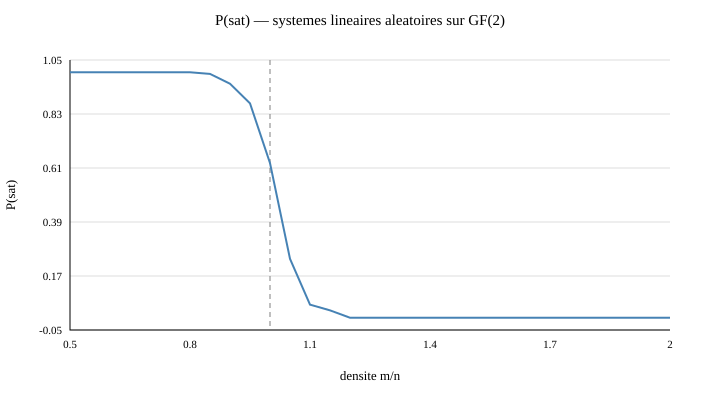

In [4]:
// Figure — P(sat) contre la densite m/n (GF(2), n=40, N=300)
Microsoft.DotNet.Interactive.Formatting.Formatter.Register<string>((value, writer) => writer.Write(value), "image/svg+xml");
Console.WriteLine("densite m/n | P(sat) mesure");
for (int i = 0; i < dens_psat.Length; i++)
    Console.WriteLine($"{dens_psat[i]:F2} | {psat[i]:F6}");
string svgPsat = graphique_svg(dens_psat, new[] { psat }, new[] { "steelblue" },
    "P(sat) — systemes lineaires aleatoires sur GF(2)", "densite m/n", "P(sat)",
    -0.05, 1.05, new[] { 1.0 });
display(svgPsat, "image/svg+xml");

### Lecture du résultat — la chute près de 1

Dans les mesures C#, $P(\text{sat})$ vaut $0{,}95$ à $m/n=0{,}90$, $0{,}87$ à $0{,}95$, $0{,}63$ à $1{,}00$ et $0{,}24$ à $1{,}05$. La référence Python citée donne respectivement $0{,}97$, $0{,}88$, $0{,}61$ et $0{,}23$ ; les tirages sont différents.

Une interpolation linéaire des mesures C# place approximativement les croisements à 90 % et 10 % à $0{,}93$ et $1{,}09$. La médiane interpolée vaut $1{,}02$ à l'arrondi, comme le calcule la section 7. Sous le seuil, les lignes sont généralement indépendantes et le système est presque toujours compatible ; au-dessus, la saturation du rang rend les équations supplémentaires susceptibles de créer des contradictions.

## 4. Le coût : un genou, pas une explosion

C'est ici que se joue la thèse. On trace, sur le **même balayage**, la quantité qui joue le rôle
du « coût » : le **rang** de $A$ (et les variables libres $n - \text{rang}$). Si ce système
cachait un mur, on y verrait une explosion au seuil. Elle n'y est pas.

In [5]:
// Les références Python ci-dessous sont arrondies à un chiffre après la virgule.
// Tolérance absolue déclarée avant le calcul : 0,35 rang, arrondi compris.
const double toleranceRang = 0.35;
int nRang = 40, NRang = 200;
double[] dens_rang = Enumerable.Range(0, 16).Select(i => 0.5 + 0.1 * i).ToArray();
double[] rang_moyens = new double[dens_rang.Length];
double[] referenceRang = { 20.0, 24.0, 28.0, 32.0, 36.0, 39.1, 39.9, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0 };
var rngRang = new Random(42);
Console.WriteLine($"Tolérance absolue aux rangs Python cités : {toleranceRang:F2} ; graine C# : 42");
Console.WriteLine("densite m/n  |  rang moyen  |  libres (n-rang)  |  m");
for (int i = 0; i < dens_rang.Length; i++)
{
    int m = (int)Math.Round(dens_rang[i] * nRang, MidpointRounding.ToEven);
    int sommeRangs = 0;
    for (int essai = 0; essai < NRang; essai++)
    {
        var instance = gen_instance(m, nRang, rngRang);
        int rang = gauss_gf2(instance.A, instance.b).rang;
        verifier(rang >= 0 && rang <= Math.Min(m, nRang), "Rang hors limites");
        sommeRangs += rang;
    }
    rang_moyens[i] = (double)sommeRangs / NRang;
    Console.WriteLine($"  {dens_rang[i],4:F2}     |  {rang_moyens[i],6:F1}      |  {nRang - rang_moyens[i],6:F1}          |  {m}");
}
// Comparer les moyennes calculées aux valeurs Python citées et arrondies.
Console.WriteLine("Comparaison : densite | C# mesure | Python cite | ecart absolu | verdict");
double ecartMaxRang = 0;
for (int i = 0; i < dens_rang.Length; i++)
{
    double ecart = Math.Abs(rang_moyens[i] - referenceRang[i]);
    ecartMaxRang = Math.Max(ecartMaxRang, ecart);
    Console.WriteLine($"{dens_rang[i]:F2} | {rang_moyens[i]:F3} | {referenceRang[i]:F1} | {ecart:F3} | {(ecart <= toleranceRang ? "CONFORME" : "ECART")}");
    verifier(ecart <= toleranceRang, "Écart de rang supérieur à la tolérance déclarée");
}

Tolérance absolue aux rangs Python cités : 0.35 ; graine C# : 42


densite m/n  |  rang moyen  |  libres (n-rang)  |  m


  0.50     |    20.0      |    20.0          |  20


  0.60     |    24.0      |    16.0          |  24


  0.70     |    28.0      |    12.0          |  28


  0.80     |    32.0      |     8.0          |  32


... (25 outputs left out)

1.70 | 40.000 | 40.0 | 0.000 | CONFORME


1.80 | 40.000 | 40.0 | 0.000 | CONFORME


1.90 | 40.000 | 40.0 | 0.000 | CONFORME


2.00 | 40.000 | 40.0 | 0.000 | CONFORME


densite m/n | rang moyen mesure


0.50 | 20.000


0.60 | 24.000


0.70 | 28.000


0.80 | 32.000


0.90 | 35.945


... (7 outputs left out)

1.70 | 40.000


1.80 | 40.000


1.90 | 40.000


2.00 | 40.000


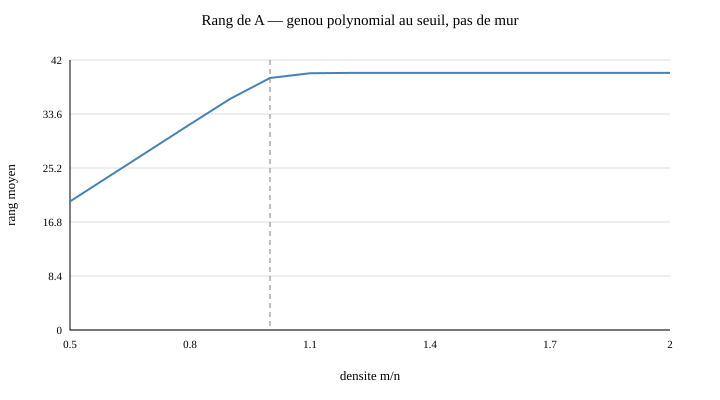

In [6]:
// Figure — rang moyen contre la densite m/n (GF(2), n=40)
Console.WriteLine("densite m/n | rang moyen mesure");
for (int i = 0; i < dens_rang.Length; i++)
    Console.WriteLine($"{dens_rang[i]:F2} | {rang_moyens[i]:F3}");
string svgRang = graphique_svg(dens_rang, new[] { rang_moyens }, new[] { "steelblue" },
    "Rang de A — genou polynomial au seuil, pas de mur", "densite m/n", "rang moyen",
    0, 42, new[] { 1.0 });
display(svgRang, "image/svg+xml");

### Lecture du résultat — le rang sature

Dans la table C#, le rang moyen vaut $35{,}9$ à $m/n=0{,}90$, $39{,}2$ à $1{,}00$ et $39{,}9$ à $1{,}10$, sur $n=40$. Les nombres correspondants de variables libres sont $4{,}1$, $0{,}8$ et $0{,}1$. La référence Python citée donne $36{,}0$, $39{,}1$ et $39{,}9$ pour les rangs.

Le rang présente un genou et sature à la dimension $n$ ; ce n'est pas une mesure directe du nombre d'opérations. L'élimination de Gauss demeure polynomiale, y compris au-delà du seuil.

## 5. Le contrôle discriminant : seuil sans pic (GF(2)) face au pic (3-SAT)

Pour que le contraste soit **mesuré et non affirmé**, on rejoue le même protocole sur le 3-SAT
(compagnon 02b) : un DPLL avec compteur de nœuds, balayé en densité autour de **son** seuil
(4,267). La comparaison des deux courbes de coût est la thèse du notebook.

In [7]:
// Un littéral positif code la variable v ; un littéral négatif code -v-1.
bool? lit_val(int lit, Dictionary<int, bool> assg)
{
    int v = lit >= 0 ? lit : -lit - 1;
    if (!assg.TryGetValue(v, out bool valeur)) return null;
    return lit >= 0 ? valeur : !valeur;
}

(bool sat, int nodes, bool plafonne) dpll_3sat(List<int[]> clauses, int node_cap = 3000)
{
    int nodes = 0;
    bool plafonne = false;
    bool rec(List<int[]> courant, Dictionary<int, bool> assg)
    {
        // cap : instance "dure"
        if (nodes > node_cap) { plafonne = true; return false; }
        nodes++;
        var simplifiees = new List<int[]>();
        foreach (var clause in courant)
        {
            bool satisfaite = false;
            var inconnus = new List<int>();
            foreach (int lit in clause)
            {
                bool? valeur = lit_val(lit, assg);
                if (valeur == true) { satisfaite = true; break; }
                if (valeur == null) inconnus.Add(lit);
            }
            if (satisfaite) continue;
            if (inconnus.Count == 0) return false; // clause vide : contradiction
            simplifiees.Add(inconnus.ToArray());
        }
        if (simplifiees.Count == 0) return true;
        int premier = simplifiees[0][0];
        int variable = premier >= 0 ? premier : -premier - 1;
        foreach (bool valeur in new[] { true, false })
        {
            var suivante = new Dictionary<int, bool>(assg);
            suivante[variable] = valeur;
            if (rec(simplifiees, suivante)) return true;
        }
        return false;
    }
    bool sat = rec(clauses, new Dictionary<int, bool>());
    return (sat, nodes, plafonne);
}

// Chaque clause choisit trois variables distinctes et trois signes indépendants.
List<int[]> gen_3sat(int n, int m, Random rng)
{
    var clauses = new List<int[]>();
    for (int i = 0; i < m; i++)
    {
        int[] disponibles = Enumerable.Range(0, n).ToArray();
        int[] vars = new int[3];
        for (int j = 0; j < 3; j++)
        {
            int k = rng.Next(j, n);
            int tmp = disponibles[j]; disponibles[j] = disponibles[k]; disponibles[k] = tmp;
            vars[j] = disponibles[j];
        }
        int[] clause = new int[3];
        for (int j = 0; j < 3; j++) clause[j] = rng.Next(2) == 1 ? vars[j] : -vars[j] - 1;
        clauses.Add(clause);
    }
    return clauses;
}

// Tolérances absolues déclarées avant calcul ; Python est cité, C# utilise System.Random.
const double toleranceSat3 = 0.40;
const double toleranceNoeuds3 = 1200.0;
double[] refSat3 = { 0.97, 0.97, 0.93, 0.88, 0.88, 0.88, 0.80, 0.78, 0.70, 0.72, 0.53, 0.42, 0.40, 0.35, 0.28, 0.17 };
double[] refNoeuds3 = { 438, 559, 713, 566, 653, 715, 721, 873, 853, 963, 1036, 1140, 1139, 1141, 1186, 1143 };
int n3 = 20, N3 = 40;
double[] dens3 = Enumerable.Range(0, 16).Select(i => 3.5 + 0.1 * i).ToArray();
double[] nodes_moyens = new double[dens3.Length];
double[] psat3 = new double[dens3.Length];
int[] plafonds3 = new int[dens3.Length];
var rng3 = new Random(42);
Console.WriteLine($"Graine C# 42 ; tolérances absolues : P(sat) {toleranceSat3:F2}, nœuds {toleranceNoeuds3:F0}.");
Console.WriteLine("densite m/n  |  P(sat)  |  noeuds DPLL moyens  (3-SAT, n=20, N=40, cap=3000)");
for (int i = 0; i < dens3.Length; i++)
{
    int m = (int)Math.Round(dens3[i] * n3, MidpointRounding.ToEven);
    int sats = 0, somme = 0;
    for (int k = 0; k < N3; k++)
    {
        var r = dpll_3sat(gen_3sat(n3, m, rng3));
        if (r.sat) sats++;
        if (r.plafonne) plafonds3[i]++;
        somme += r.nodes;
        verifier(r.nodes >= 1 && r.nodes <= 3001, "Compteur DPLL hors limites");
    }
    psat3[i] = (double)sats / N3;
    nodes_moyens[i] = (double)somme / N3;
    Console.WriteLine($"  {dens3[i],4:F2}     |  {psat3[i],4:F2}  |  {nodes_moyens[i],10:F0}");
}
Console.WriteLine("densite | ecart P(sat) Python cite | ecart noeuds Python cite | plafonds | verdict");
double ecartMaxSat3 = 0, ecartMaxNoeuds3 = 0;
for (int i = 0; i < dens3.Length; i++)
{
    double ep = Math.Abs(psat3[i] - refSat3[i]);
    double en = Math.Abs(nodes_moyens[i] - refNoeuds3[i]);
    ecartMaxSat3 = Math.Max(ecartMaxSat3, ep);
    ecartMaxNoeuds3 = Math.Max(ecartMaxNoeuds3, en);
    bool conforme = ep <= toleranceSat3 && en <= toleranceNoeuds3;
    Console.WriteLine($"{dens3[i]:F2} | {ep:F3} | {en:F1} | {plafonds3[i]} | {(conforme ? "CONFORME" : "ECART")}");
    verifier(conforme, "Écart 3-SAT supérieur à la tolérance déclarée");
}
Console.WriteLine("Les verdicts négatifs après plafond sont indéterminés ; la fréquence reproduit la convention bornée de la source.");

Graine C# 42 ; tolérances absolues : P(sat) 0.40, nœuds 1200.


densite m/n  |  P(sat)  |  noeuds DPLL moyens  (3-SAT, n=20, N=40, cap=3000)


  3.50     |  0.97  |         515


  3.60     |  0.95  |         567


  3.70     |  0.90  |         640


  3.80     |  0.93  |         839


... (26 outputs left out)

4.80 | 0.050 | 137.5 | 0 | CONFORME


4.90 | 0.005 | 84.6 | 0 | CONFORME


5.00 | 0.080 | 121.7 | 0 | CONFORME


Les verdicts négatifs après plafond sont indéterminés ; la fréquence reproduit la convention bornée de la source.


In [8]:
// Validation du DPLL 3-SAT contre l'enumeration exhaustive (memorandum de l'oracle h6)
bool exhaustive_3sat(List<int[]> clauses, int n)
{
    for (int x = 0; x < (1 << n); x++)
    {
        bool toutes = true;
        foreach (var clause in clauses)
        {
            bool satisfaite = false;
            foreach (int lit in clause)
            {
                int v = lit >= 0 ? lit : -lit - 1;
                bool valeur = ((x >> v) & 1) != 0;
                if (lit < 0) valeur = !valeur;
                if (valeur) { satisfaite = true; break; }
            }
            if (!satisfaite) { toutes = false; break; }
        }
        if (toutes) return true;
    }
    return false;
}
// Le plafond élevé ne doit pas être atteint pendant le contrôle.
var rngOracle3 = new Random(42);
int disa = 0, trie = 0, plafondsOracle3 = 0;
for (int nOracle3 = 6; nOracle3 <= 10; nOracle3++)
    for (int k = 0; k < 15; k++)
    {
        int m = rngOracle3.Next(1, 2 * nOracle3 + 1);
        var clauses = gen_3sat(nOracle3, m, rngOracle3);
        var resultat = dpll_3sat(clauses, 1000000);
        trie++;
        if (resultat.plafonne) plafondsOracle3++;
        if (resultat.sat != exhaustive_3sat(clauses, nOracle3)) disa++;
    }
Console.WriteLine($"instances 3-SAT testees : {trie}  (n = 6..10)");
Console.WriteLine($"desaccords DPLL vs enumeration exhaustive : {disa}");
verifier(trie == 75 && disa == 0 && plafondsOracle3 == 0, "Échec du contrôle DPLL ou plafond atteint");

instances 3-SAT testees : 75  (n = 6..10)


desaccords DPLL vs enumeration exhaustive : 0


densite m/n | noeuds DPLL moyens | plafonds atteints


3.50 | 515.000 | 0


3.60 | 566.875 | 0


3.70 | 639.825 | 0


3.80 | 838.900 | 0


3.90 | 595.950 | 0


... (7 outputs left out)

4.70 | 1046.150 | 0


4.80 | 1278.500 | 0


4.90 | 1101.425 | 0


5.00 | 1264.725 | 0


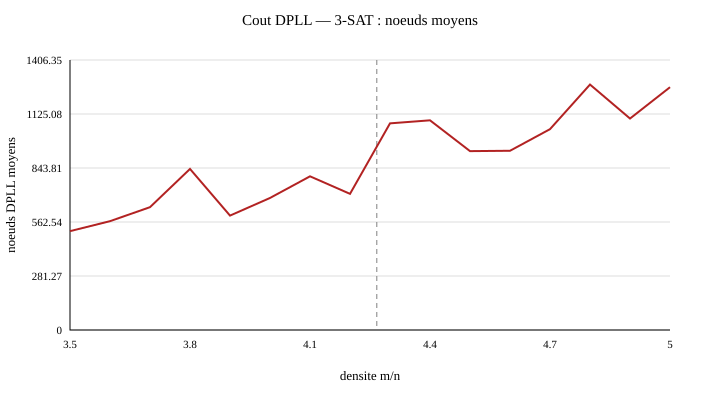

In [9]:
// Figure — noeuds DPLL moyens contre la densite m/n (3-SAT, n=20, N=40, cap=3000)
Console.WriteLine("densite m/n | noeuds DPLL moyens | plafonds atteints");
for (int i = 0; i < dens3.Length; i++)
    Console.WriteLine($"{dens3[i]:F2} | {nodes_moyens[i]:F3} | {plafonds3[i]}");
string svg3 = graphique_svg(dens3, new[] { nodes_moyens }, new[] { "firebrick" },
    "Cout DPLL — 3-SAT : noeuds moyens", "densite m/n", "noeuds DPLL moyens",
    0, Math.Max(1, nodes_moyens.Max() * 1.1), new[] { 4.267 });
display(svg3, "image/svg+xml");

### Lecture du résultat — le DPLL est vérifié, puis son coût monte avec la densité

Zéro désaccord entre le DPLL et l'énumération exhaustive sur les 75 instances 3-SAT tirées (n = 6 à 10), sans plafond atteint : le compteur de nœuds mesure bien un solveur correct. Sur le balayage, la fréquence $P(\text{sat})$ passe de $0{,}97$ à $m/n = 3{,}5$ à $0{,}25$ à $5{,}0$, tandis que les nœuds moyens passent de $515$ à $1265$, avec un maximum de $1278{,}5$ à $4{,}80$ ; la courbe est bruitée ($N = 40$ tirages par point) et seuls deux points ($4{,}20$ et $4{,}40$) ont touché le plafond une fois.

### La figure comparative — le même balayage de densité pour les deux familles

Les deux figures précédentes sont **séparées** : le coût du GF(2) est tracé sur $[0{,}5 ; 2]$ et
celui du 3-SAT sur $[3{,}5 ; 5]$. On ne peut donc pas lire la comparaison d'un trait à l'autre. La
figure ci-dessous remesure **les deux familles sur la même grille de densité** — de $0{,}5$ à $5$ —
et trace les deux coûts **normalisés** (1 = maximum de la courbe) : le coût est ainsi comparé par
sa **forme**, sans mélanger les unités (le rang d'une matrice n'est pas un nombre de nœuds de DPLL).

Ce que la figure doit faire apparaître : la courbe du GF(2) **sature sans jamais culminer** — un
genou, pas un pic — tandis que celle du 3-SAT **culmine** au voisinage de son seuil (le $4{,}267$ de
02b est **cité** ; la position du maximum mesuré ici est un **Mesuré**, à la précision de $n = 20$ et
$N = 40$ près).

Graines C# 42 ; tolérances absolues : rang 0.50, nœuds 1200.


Tolérances aux références Python citées : densité du pic 0.80, maximum 400 nœuds, facteurs rang 0.10 et DPLL 35.0.


densite m/n | rang moyen GF(2) | noeuds DPLL 3-SAT | normalises (GF2 / 3SAT)


0.50 | 20.000 | 11.800 | 0.500000 / 0.010145


0.60 | 24.000 | 13.625 | 0.600000 / 0.011714


0.70 | 28.000 | 15.425 | 0.700000 / 0.013261


... (55 outputs left out)

2.00 | 0.000 | 14.200 | CONFORME


3.50 | 0.000 | 30.450 | CONFORME


4.30 | 0.000 | 275.600 | CONFORME


5.00 | 0.000 | 21.250 | CONFORME


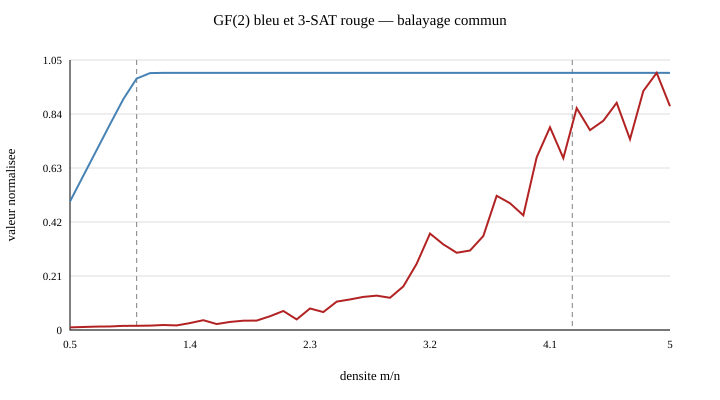

In [10]:
// Figure comparative — le meme balayage de densite pour les deux familles (0,5 a 5,0)
// Les deux couts sont normalises par leur propre maximum (1 = maximum de la courbe) :
// on compare les FORMES (un genou sans pic face a un pic), pas des unites differentes
// (le rang d'une matrice n'est pas un nombre de noeuds de DPLL).
// Tolérances absolues aux références Python arrondies, déclarées avant calcul.
const double toleranceRangCommun = 0.50;
const double toleranceNoeudsCommun = 1200.0;
// Le maximum et sa position sont sensibles au bruit de 40 tirages par densité.
// Les marges autorisent un déplacement de huit pas et 400 nœuds ; le facteur
// DPLL cumule en outre les fluctuations des deux extrémités du balayage.
const double toleranceDensitePic = 0.80;
const double toleranceMaximumDpll = 400.0;
const double toleranceFacteurRang = 0.10;
const double toleranceFacteurDpll = 35.0;
double[] dens_commun = Enumerable.Range(0, 46).Select(i => 0.5 + 0.1 * i).ToArray();
double[] rang_commun = new double[dens_commun.Length];
double[] noeuds_commun = new double[dens_commun.Length];
var rngX = new Random(42);
var rngS = new Random(42);
Console.WriteLine($"Graines C# 42 ; tolérances absolues : rang {toleranceRangCommun:F2}, nœuds {toleranceNoeudsCommun:F0}.");
Console.WriteLine($"Tolérances aux références Python citées : densité du pic {toleranceDensitePic:F2}, maximum {toleranceMaximumDpll:F0} nœuds, facteurs rang {toleranceFacteurRang:F2} et DPLL {toleranceFacteurDpll:F1}.");
for (int i = 0; i < dens_commun.Length; i++)
{
    int m = (int)Math.Round(dens_commun[i] * 40, MidpointRounding.ToEven);
    int somme = 0;
    for (int k = 0; k < 100; k++)
    {
        var instance = gen_instance(m, 40, rngX);
        int rang = gauss_gf2(instance.A, instance.b).rang;
        verifier(rang >= 0 && rang <= Math.Min(m, 40), "Rang commun hors limites");
        somme += rang;
    }
    rang_commun[i] = somme / 100.0;
}
int plafondsCommun = 0;
for (int i = 0; i < dens_commun.Length; i++)
{
    int m = (int)Math.Round(dens_commun[i] * 20, MidpointRounding.ToEven);
    int somme = 0;
    for (int k = 0; k < 40; k++)
    {
        var resultat = dpll_3sat(gen_3sat(20, m, rngS));
        somme += resultat.nodes;
        if (resultat.plafonne) plafondsCommun++;
        verifier(resultat.nodes >= 1 && resultat.nodes <= 3001, "Compteur DPLL commun hors limites");
    }
    noeuds_commun[i] = somme / 40.0;
}
double maxRangCommun = rang_commun.Max(), maxNoeudsCommun = noeuds_commun.Max();
verifier(maxRangCommun > 0 && maxNoeudsCommun > 0, "Normalisation impossible");
double[] rangNorm = rang_commun.Select(v => v / maxRangCommun).ToArray();
double[] noeudsNorm = noeuds_commun.Select(v => v / maxNoeudsCommun).ToArray();
Console.WriteLine("densite m/n | rang moyen GF(2) | noeuds DPLL 3-SAT | normalises (GF2 / 3SAT)");
for (int i = 0; i < dens_commun.Length; i++)
    Console.WriteLine($"{dens_commun[i]:F2} | {rang_commun[i]:F3} | {noeuds_commun[i]:F3} | {rangNorm[i]:F6} / {noeudsNorm[i]:F6}");
int iPeak = Array.IndexOf(noeuds_commun, maxNoeudsCommun);
double facteurRang = rang_commun[rang_commun.Length - 1] / rang_commun[0];
double facteurDpll = noeuds_commun[noeuds_commun.Length - 1] / noeuds_commun[0];
Console.WriteLine($"pic DPLL mesure : m/n = {dens_commun[iPeak]:F2} ({maxNoeudsCommun:F0} noeuds moyens)");
Console.WriteLine($"facteurs de croissance sur le balayage : rang GF(2) x{facteurRang:F1} , noeuds DPLL x{facteurDpll:F1}");
Console.WriteLine($"Instances ayant atteint le plafond : {plafondsCommun}");
// Les références ci-dessous sont les sorties arrondies du jumeau Python, citées.
void comparerCommun(string nom, double mesure, double cite, double tolerance)
{
    double ecart = Math.Abs(mesure - cite);
    Console.WriteLine($"{nom} | C# mesure {mesure:F3} | Python cite {cite:F3} | ecart {ecart:F3} | tolerance {tolerance:F3} | {(ecart <= tolerance ? "CONFORME" : "ECART")}");
    verifier(ecart <= tolerance, "Écart à la référence Python : " + nom);
}
comparerCommun("densité du pic DPLL", dens_commun[iPeak], 4.60, toleranceDensitePic);
comparerCommun("maximum DPLL", maxNoeudsCommun, 1270.0, toleranceMaximumDpll);
comparerCommun("facteur de croissance du rang", facteurRang, 2.0, toleranceFacteurRang);
comparerCommun("facteur de croissance DPLL", facteurDpll, 76.9, toleranceFacteurDpll);
int[] indicesRefCommun = { 0, 3, 5, 7, 15, 30, 38, 45 };
double[] refRangCommun = { 20.0, 32.0, 39.1, 40.0, 40.0, 40.0, 40.0, 40.0 };
double[] refNoeudsCommun = { 13, 17, 17, 20, 48, 329, 728, 991 };
double ecartMaxRangCommun = 0, ecartMaxNoeudsCommun = 0;
Console.WriteLine("densite | ecart rang Python cite | ecart noeuds Python cite | verdict");
for (int j = 0; j < indicesRefCommun.Length; j++)
{
    int i = indicesRefCommun[j];
    double er = Math.Abs(rang_commun[i] - refRangCommun[j]);
    double en = Math.Abs(noeuds_commun[i] - refNoeudsCommun[j]);
    ecartMaxRangCommun = Math.Max(ecartMaxRangCommun, er);
    ecartMaxNoeudsCommun = Math.Max(ecartMaxNoeudsCommun, en);
    bool conforme = er <= toleranceRangCommun && en <= toleranceNoeudsCommun;
    Console.WriteLine($"{dens_commun[i]:F2} | {er:F3} | {en:F3} | {(conforme ? "CONFORME" : "ECART")}");
    verifier(conforme, "Écart du balayage commun supérieur à la tolérance déclarée");
}
string svgCommun = graphique_svg(dens_commun, new[] { rangNorm, noeudsNorm }, new[] { "steelblue", "firebrick" },
    "GF(2) bleu et 3-SAT rouge — balayage commun", "densite m/n", "valeur normalisee",
    0, 1.05, new[] { 1.0, 4.267 });
display(svgCommun, "image/svg+xml");

### Lecture du résultat — la thèse : le seuil n'implique pas le mur

Le 3-SAT voit son coût augmenter sur le balayage de densité, tandis que la fréquence des verdicts satisfaisables diminue. À cette taille et avec ce plafond, la localisation d'un pic reste incertaine ; le seuil de 4,267 indiqué par 02b est **Cité**. Le système GF(2), lui, présente un seuil de satisfaisabilité net alors que son rang sature : un genou, pas une explosion.

La figure comparative mesure les deux familles **sur la même grille**. Le rang moyen de GF(2) sature à 40, la dimension du problème, vers $m/n = 1{,}2$ ; il croît d'un facteur **× 2,0** sur le balayage. Les nœuds DPLL augmentent fortement, mais le maximum mesuré dépend des tirages : la source Python cite un maximum à $m/n = 4{,}60$, tandis que la table précédente donne les mesures de ce carnet, obtenues avec un générateur différent.

Ce contraste montre qu'un seuil de satisfaisabilité n'implique pas à lui seul un mur de coût. Le rang est ici un indicateur de structure, tandis que les nœuds DPLL mesurent le travail d'un solveur particulier ; ces mesures finies ne constituent pas à elles seules une preuve de complexité exponentielle.

## 6. L'affûtage avec n : la bande se resserre

Une transition de phase **s'aiguïse** quand le système grossit. À densité fixe au-dessus du seuil,
si la matrice est de rang plein, la probabilité de compatibilité conditionnelle vaut $2^{-(m-n)}$.
Elle décroît alors **exponentiellement** avec $n$. À taille finie, le déficit de rang modifie la
probabilité ; les fréquences mesurées comportent aussi des fluctuations d'échantillonnage.

In [11]:
// Les références Python sont citées et arrondies ; le générateur C# est distinct.
// Tolérance absolue déclarée avant les tirages : 0,15, incluant fluctuation et arrondi.
const double toleranceAffutage = 0.15;
int[] taillesAffutage = { 10, 20, 40, 60 };
double[] refAffutage = { 0.217, 0.058, 0.000, 0.000 };
// Valeurs exactes de 2^{-(m-n)} pour les quatre tailles et m = 1,2 n.
double[] refTheoriqueAffutage = { 0.25, 0.0625, 0.00390625, 0.000244140625 };
double[] mesuresAffutage = new double[taillesAffutage.Length];
var rngAffutage = new Random(42);
double ecartMaxAffutage = 0;
Console.WriteLine($"Graine C# : 42 ; tolérance absolue aux valeurs Python citées : {toleranceAffutage:F2}");
Console.WriteLine("n   |  m/n=1.2  |  P(sat) mesure  |  2^{-(m-n)} theorique");
for (int i = 0; i < taillesAffutage.Length; i++)
{
    int n = taillesAffutage[i];
    int m = (int)Math.Round(1.2 * n, MidpointRounding.ToEven);
    int sat = 0;
    for (int k = 0; k < 400; k++)
    {
        var instance = gen_instance(m, n, rngAffutage);
        if (gauss_gf2(instance.A, instance.b).sat) sat++;
    }
    mesuresAffutage[i] = sat / 400.0;
    double theorique = Math.Pow(2.0, -(m - n));
    Console.WriteLine($"{n,3} |  1.20      |  {mesuresAffutage[i],6:F3}          |  {theorique,6:F3}");
    verifier(theorique == refTheoriqueAffutage[i], "Valeur théorique différente de la référence exacte");
    verifier(mesuresAffutage[i] >= 0 && mesuresAffutage[i] <= 1, "Fréquence hors limites");
}
Console.WriteLine("n | theorique calcule | attendu exact | ecart");
for (int i = 0; i < taillesAffutage.Length; i++)
{
    int m = (int)Math.Round(1.2 * taillesAffutage[i], MidpointRounding.ToEven);
    double theorique = Math.Pow(2.0, -(m - taillesAffutage[i]));
    Console.WriteLine($"{taillesAffutage[i]} | {theorique:F12} | {refTheoriqueAffutage[i]:F12} | {Math.Abs(theorique - refTheoriqueAffutage[i]):F12}");
}
// Les écarts aux valeurs citées ne sont pas des tirages Python recalculés.
Console.WriteLine("n | C# mesure | Python cite | ecart absolu | verdict");
for (int i = 0; i < taillesAffutage.Length; i++)
{
    double ecart = Math.Abs(mesuresAffutage[i] - refAffutage[i]);
    ecartMaxAffutage = Math.Max(ecartMaxAffutage, ecart);
    bool conforme = ecart <= toleranceAffutage;
    Console.WriteLine($"{taillesAffutage[i]} | {mesuresAffutage[i]:F3} | {refAffutage[i]:F3} | {ecart:F3} | {(conforme ? "CONFORME" : "ECART")}");
    verifier(conforme, "Écart d'affûtage supérieur à la tolérance déclarée");
}

Graine C# : 42 ; tolérance absolue aux valeurs Python citées : 0.15


n   |  m/n=1.2  |  P(sat) mesure  |  2^{-(m-n)} theorique


 10 |  1.20      |   0.200          |   0.250


 20 |  1.20      |   0.058          |   0.062


 40 |  1.20      |   0.000          |   0.004


 60 |  1.20      |   0.000          |   0.000


... (6 outputs left out)

10 | 0.200 | 0.217 | 0.017 | CONFORME


20 | 0.058 | 0.058 | 0.001 | CONFORME


40 | 0.000 | 0.000 | 0.000 | CONFORME


60 | 0.000 | 0.000 | 0.000 | CONFORME


### Lecture du résultat — la transition s'aiguïse

À densité $1{,}2$, les mesures C# sont $0{,}200$, $0{,}058$, $0{,}000$ et $0{,}000$ pour les tailles successives de la table. La référence Python cite respectivement $0{,}217$, $0{,}058$, $0{,}000$ et $0{,}000$. La formule $2^{-(m-n)}$ donne $0{,}250$, environ $0{,}062$, $0{,}004$ et une valeur arrondie à $0{,}000$.

La fréquence passe ainsi de 20 % à zéro observé entre $n=10$ et $n=40$ ; une fréquence observée nulle ne prouve pas que la probabilité soit nulle. La formule indiquée décrit le comportement lorsque la matrice a rang plein ; à taille finie, le déficit de rang et les fluctuations d'échantillonnage affectent la comparaison.

## 7. Résolution et épistémologie : Cité contre Mesuré

La **position** du seuil est un **théorème** : le rang générique d'une matrice aléatoire
$m \times n$ sur $\mathrm{GF}(2)$ bascule à $m = n$, d'où le seuil exact $m/n = 1$. C'est un
résultat **Cité**. La **bande** que nous avons mesurée est un résultat **Mesuré**, et elle doit
être cohérente avec le théorème dans la limite de la résolution de l'échantillon.

In [12]:
int NSeuil = 300;
double errSeuil = 1.0 / Math.Sqrt(NSeuil);
// Mesure : densite ou P(sat) croise 0,5, par interpolation sur les points de la section 3
double cross = double.NaN;
for (int i = 0; i < psat.Length - 1; i++)
{
    if ((psat[i] - 0.5) * (psat[i + 1] - 0.5) <= 0 && psat[i] != psat[i + 1])
    {
        double t = (0.5 - psat[i]) / (psat[i + 1] - psat[i]);
        cross = dens_psat[i] + t * (dens_psat[i + 1] - dens_psat[i]);
    }
}
verifier(!double.IsNaN(cross), "Aucun croisement interpolable à 0,5");
double ecartSeuil = Math.Abs(cross - 1.0);
bool coherentSeuil = ecartSeuil <= 2 * errSeuil;
Console.WriteLine("seuil theorique (Cite)  : 1.00  (le rang generique bascule a m = n)");
Console.WriteLine($"P(sat) croise 0,5 a     : {cross:F2}   (mesure par interpolation, N={NSeuil})");
Console.WriteLine($"ecart a la theorie      : {ecartSeuil:F2}   (borne 1/sqrt(N) = {errSeuil:F3})");
Console.WriteLine($"coherent avec le theoreme : {coherentSeuil}");
// Tolérance déclarée et annoncée en section 3, avant les tirages de la courbe.
double ecartCroisementPython = Math.Abs(cross - 1.01);
Console.WriteLine($"Python cite : 1.01 ; ecart absolu : {ecartCroisementPython:F3} ; tolerance : {toleranceCroisement:F2}");
verifier(coherentSeuil, "Croisement hors du critère déclaré");
verifier(ecartCroisementPython <= toleranceCroisement, "Écart au croisement Python cité trop grand");

seuil theorique (Cite)  : 1.00  (le rang generique bascule a m = n)


P(sat) croise 0,5 a     : 1.02   (mesure par interpolation, N=300)


ecart a la theorie      : 0.02   (borne 1/sqrt(N) = 0.058)


coherent avec le theoreme : True


Python cite : 1.01 ; ecart absolu : 0.007 ; tolerance : 0.12


### Lecture du résultat — Cité et Mesuré

Le croisement C# interpolé s'affiche à $1{,}02$, contre $1{,}01$ pour la référence Python citée. Son écart affiché au seuil cité $1{,}00$ est $0{,}02$. Il satisfait le critère du carnet, à savoir un écart inférieur à deux fois $1/\sqrt{300} \approx 0{,}058$. Cette borne est un critère de comparaison choisi ici ; elle ne constitue pas à elle seule un intervalle de confiance pour la densité interpolée.

## 8. Exercices

Trois exercices, exécutables sans erreur volontaire (stubs non bloquants).

In [13]:
// Exercice 1 : complétez la fonction qui renvoie le nombre de variables libres
// d'un systeme sur GF(2) satisfaisable. Indice : c'est n - rang(A) (cf. gauss_gf2).
int? nombre_variables_libres(int[,] A, int[] b)
{
    // TODO etudiant
    return null;
}
Console.WriteLine("Exercice a completer");

Exercice a completer


In [14]:
// Exercice 2 : a quelle densite m/n le systeme lineaire aléatoire sur GF(2)
// bascule-t-il de satisfaisable a non-satisfaisable ? Justifiez par le mecanisme de rang.
// TODO etudiant
Console.WriteLine("Exercice a completer");

Exercice a completer


In [15]:
// Exercice 3 : pourquoi le cout (rang / operations d'elimination) du systeme GF(2)
// ne forme-t-il PAS de pic au seuil, alors que le 3-SAT en forme un ?
// TODO etudiant
Console.WriteLine("Exercice a completer");

Exercice a completer


## À retenir

Les systèmes linéaires aléatoires denses sur $\mathrm{GF}(2)$ présentent un seuil de satisfaisabilité près de $m/n=1$, tandis que leur résolution par élimination de Gauss reste polynomiale. Dans les mesures C#, le rang moyen vaut $39{,}2$ à $m/n=1$ et $39{,}9$ à $1{,}1$ ; la médiane interpolée de $P(\text{sat})$ s'affiche à $1{,}02$. À densité $1{,}2$, la fréquence observée passe de $20\,\%$ à $n=10$ à zéro observé à $n=40$.

Les valeurs Python citées dans les comparaisons diffèrent car les générateurs produisent des tirages distincts. Le contrôle 3-SAT montre une augmentation du nombre de nœuds DPLL sur le balayage : ce compteur et le rang ne mesurent pas la même quantité, et les expériences finies ne prouvent pas à elles seules une complexité exponentielle. Le message central est qu'un seuil de satisfaisabilité n'implique pas à lui seul un mur de coût.

## Vérifiez votre compréhension

1. Entre les densités $0{,}95$ et $1{,}10$, les mesures C# de $P(\text{sat})$ passent de $0{,}87$ à $0{,}05$ ($n=40$, $N=300$). Quel mécanisme algébrique place la bascule près de $m=n$ ?
2. À densité $1{,}2$, la mesure C# donne $0{,}200$ à $n=10$, contre $2^{-(m-n)}=0{,}250$. Pourquoi cette formule est-elle une approximation à taille finie ?
3. En 3-SAT, les mesures C# passent de $0{,}97$ à $3{,}5$ à $0{,}25$ à $5{,}0$, tandis que les nœuds moyens passent de 515 à 1 265. Que peut-on déduire de cette comparaison avec GF(2) ?
4. Le croisement C# interpolé s'affiche à $1{,}02$ et le seuil cité à $1{,}00$. Est-il conforme au critère de la section 7 ?

<details><summary>Réponses</summary>

1. Le rang croît puis sature à $n$ ; des équations supplémentaires peuvent rendre le système incompatible.
2. La formule correspond au cas de rang plein. À taille finie, un déficit de rang et les fluctuations des 400 tirages affectent la fréquence.
3. Un seuil ne suffit pas à établir un mur de coût. Les nœuds DPLL mesurent le travail d'un solveur particulier, contrairement au rang ; les données finies ne prouvent pas une croissance exponentielle.
4. Oui : l'écart affiché $0{,}02$ est inférieur à $2/\sqrt{300}$.

</details>

## Pour aller plus loin

- **Carnet suivant** : [Complexity-03 — Plus de temps, plus de problèmes](Complexity-03-HierarchieTemporelle-Python.ipynb) — le seuil sans le mur pose la question du prix exact du temps : une hiérarchie de classes.
- **Jumeau Python** → [Complexity-02c-XOR-SAT-Phase-Transition-Python](Complexity-02c-XOR-SAT-Phase-Transition-Python.ipynb) — le carnet d'origine, en Python.
- **Dans la même série** : [Complexity-02b — 3-SAT : la transition de phase et le mur](Complexity-02b-SAT-PhaseTransition-Python.ipynb) — le même phénomène de seuil, cette fois avec le pic exponentiel de DPLL ; [Complexity-02 — Vérifier ou trouver : P, NP et la réduction](Complexity-02-P-NP-Reduction-Python.ipynb) — la réduction qui transporte le mur.
- **Carnet voisin d'une autre série** : [Z3-01 — Introduction (Python)](../../SymbolicAI/SMT/Z3-API/Z3-01-Introduction-Python.ipynb) — poser le même système d'équations à un solveur SMT : il répond sans voir le seuil que vous venez de mesurer.
- **Lectures** : le théorème de seuil (Friedgut) et la prédiction 4,267 sont discutés et référencés au §6 de [Complexity-02b](Complexity-02b-SAT-PhaseTransition-Python.ipynb).